In [3]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict

In [4]:
class BatsmanState(TypedDict):
    runs : int
    balls : int
    fours : int
    sixes : int

    sr : float
    bpb : int
    bp : float
    summary : str

In [12]:
#partial state
def Strikerate(state : BatsmanState):
    #50 => 100
    #100/50 = 2*100 = 200
    #runs/balls * 100
    sr = (state['runs']/state['balls'])*100

    return {"sr":sr}

In [13]:
def BallperBound(state : BatsmanState):
    #balls 100 
    #boun 20
    #100/20 => 5, balls/boundaries
    balls = state['balls']
    fours = state['fours']
    sixes = state['sixes']
    boundary = fours + sixes
    bpb = balls//boundary

    return {"bpb":bpb}


In [14]:
def BoundaryPer(state:BatsmanState)->BatsmanState:
    #100
    #10 *4 = 40
    #5 * 6 = 30 
    #70/100*100 => 70%
    bp = ((state['fours']*4 + state['sixes']*6)/state['runs'])*100

    return {"bp" : bp}

In [15]:
def Summary(state : BatsmanState)->BatsmanState:
    summary = f"""
    Strike rate : {state['sr']} \n
    Balls per boundary : {state['bpb']} \n
    Boundary percentage : {state['bp']}
    """

    state['summary'] = summary
    return state

In [16]:

graph = StateGraph(BatsmanState)

#add node
graph.add_node("Strikerate",Strikerate)
graph.add_node("BallperBound",BallperBound)
graph.add_node("BoundaryPer",BoundaryPer)
graph.add_node("Summary",Summary)

#add edge 
graph.add_edge(START,"Strikerate")
graph.add_edge(START,"BallperBound")
graph.add_edge(START,"BoundaryPer")

graph.add_edge("Strikerate","Summary")
graph.add_edge("BallperBound","Summary")
graph.add_edge("BoundaryPer","Summary")

graph.add_edge("Summary",END)

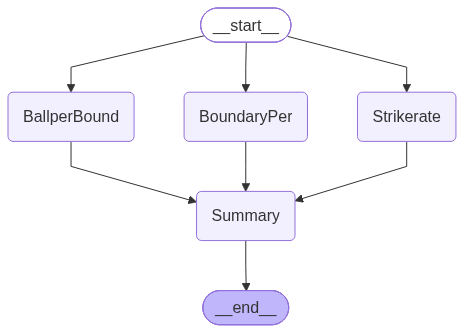

In [17]:
workflow = graph.compile()
workflow

In [18]:
initial_state = {
    "runs" : 100,
    "balls" : 50,
    "fours" : 10,
    "sixes" : 5
}

final_state = workflow.invoke(initial_state)

In [19]:
final_state

{'runs': 100,
 'balls': 50,
 'fours': 10,
 'sixes': 5,
 'sr': 200.0,
 'bpb': 3,
 'bp': 70.0,
 'summary': '\n    Strike rate : 200.0 \n\n    Balls per boundary : 3 \n\n    Boundary percentage : 70.0\n    '}

In [20]:
#essay => 
#Language => score 
#analysy -> score
#thaught -> score

#final feedback => score 